In [1]:
TrainData_name = 'Mawqif_AllTargets_Train.csv'
TestData_name = 'Mawqif_AllTargets_Test.csv'

Enable_TargetSpecefic = 'Yes' #
#selectedTarget = 'All'
#selectedTarget = 'Covid Vaccine'
#selectedTarget = 'Digital Transformation'
selectedTarget = 'Women empowerment'

Weight = "W3"

Ex_name = Weight+'_'+'MTL_'+selectedTarget

#"UBC-NLP/MARBERT
#"aubmindlab/bert-base-arabertv02"
#"CAMeL-Lab/bert-base-arabic-camelbert-da"
model_name = "aubmindlab/bert-base-arabertv02-twitter"

# Environment Settings

In [2]:
import torch

# If there's a GPU available...
if torch.cuda.is_available():    

    # Tell PyTorch to use the GPU.    
    device = torch.device("cuda")

    print('There are %d GPU(s) available.' % torch.cuda.device_count())

    print('We will use the GPU:', torch.cuda.get_device_name(0))
    !nvidia-smi

# If not...
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
We will use the GPU: NVIDIA GeForce RTX 2080 Ti
Tue Dec 27 10:51:54 2022       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 495.29.05    Driver Version: 495.29.05    CUDA Version: 11.5     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  NVIDIA GeForce ...  On   | 00000000:01:00.0 Off |                  N/A |
| 26%   31C    P8    22W / 260W |    236MiB / 11019MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
          

In [3]:
!pip install transformers datasets --quiet
!pip install farasapy==0.0.14 --quiet
!pip install PyArabic==0.6.14 --quiet 

In [4]:
# Import Basics
import pandas as pd
import numpy as np
import random
from tqdm.auto import tqdm
import pickle
import re
import os
import sys

from dataclasses import dataclass, field
from typing import Optional
import datasets
from datasets import ClassLabel, load_dataset, Dataset, DatasetDict
import string
from typing import Dict ,List


In [5]:
# Import for models
import transformers
from transformers import AutoTokenizer, AutoModel

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import torch.nn as nn


In [6]:
# Visualisation
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from matplotlib import rc

%matplotlib inline
%config InlineBackend.figure_format='retina'
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
rcParams['figure.figsize'] = 16, 10
tqdm.pandas()

# Prepare data

## Load data to colab drive

In [7]:
df = pd.read_csv(TrainData_name)
test_df = pd.read_csv(TestData_name)

## Label mapping

In [8]:
# Stance
mapping_stance = {'None': 2, 'Favor': 1, 'Against': 0}

df['stance'] = df['stance'].apply(lambda x: mapping_stance[x])
test_df['stance'] = test_df['stance'].apply(lambda x: mapping_stance[x])

# Sentiment
mapping_sent = {'Neutral': 2, 'Positive': 1, 'Negative': 0}

df['sentiment'] = df['sentiment'].apply(lambda x: mapping_sent[x])
test_df['sentiment'] = test_df['sentiment'].apply(lambda x: mapping_sent[x])

# Sarcasm
mapping_sarcasm = {"Yes": 1, "No": 0}

df['sarcasm'] = df['sarcasm'].apply(lambda x: mapping_sarcasm[x])
test_df['sarcasm'] = test_df['sarcasm'].apply(lambda x: mapping_sarcasm[x])

In [9]:
# Mapping targets

'''
mapping_targets = {'Women empowerment': 'تمكين المرأة', 'Digital Transformation': 'التحول الرقمي', 'Covid Vaccine': 'لقاح كورونا'}

df['target'] = df['target'].apply(lambda x: mapping_targets[x])
test_df['target'] = test_df['target'].apply(lambda x: mapping_targets[x])
'''

"\nmapping_targets = {'Women empowerment': 'تمكين المرأة', 'Digital Transformation': 'التحول الرقمي', 'Covid Vaccine': 'لقاح كورونا'}\n\ndf['target'] = df['target'].apply(lambda x: mapping_targets[x])\ntest_df['target'] = test_df['target'].apply(lambda x: mapping_targets[x])\n"

## Data Analysis

In [10]:
print(df.shape)
print(test_df.shape)

(3502, 14)
(619, 14)


In [11]:
test_df.head()

,ID,text,target,stance,stance:confidence,against_reason,favor_reason,none_reason,sarcasm,sarcasm:confidence,sentiment,sentiment:confidence,datetime,Date
0,2,الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحي...,Women empowerment,0,1.0000,A_Explicit,NaN,NaN,0,1.0000,0,1.0000,2022-01-26 21:46:08+00:00,26/01/2022
1,5,الفساد الإداري انهك البلاد ومازلنا نعتمد عل...,Digital Transformation,1,1.0000,NaN,F_Explicit,NaN,0,1.0000,2,0.4227,2022-03-22 08:30:35+00:00,22/03/2022
2,14,-البي بي سي ١٠ دول اوروبية توقف تطعيم اوكسفورد...,Covid Vaccine,0,0.8226,A_Explicit,NaN,NaN,0,0.8577,0,1.0000,2021-03-12 05:33:54+00:00,12/03/2021
3,16,منصة مدرستي بتسرع عملية التحول للتعليم الالكتر...,Digital Transformation,1,0.7433,NaN,F_Explicit,NaN,0,1.0000,1,0.6393,2020-08-27 09:21:25+00:00,27/08/2020
4,17,انا مع تمكين المرأة اصلا URL,Women empowerment,1,1.0000,NaN,F_Explicit,NaN,0,1.0000,1,0.8191,2022-05-16 23:47:42+00:00,16/05/2022


In [12]:
df['stance'].value_counts()

1    2148
0    1021
2     333
Name: stance, dtype: int64

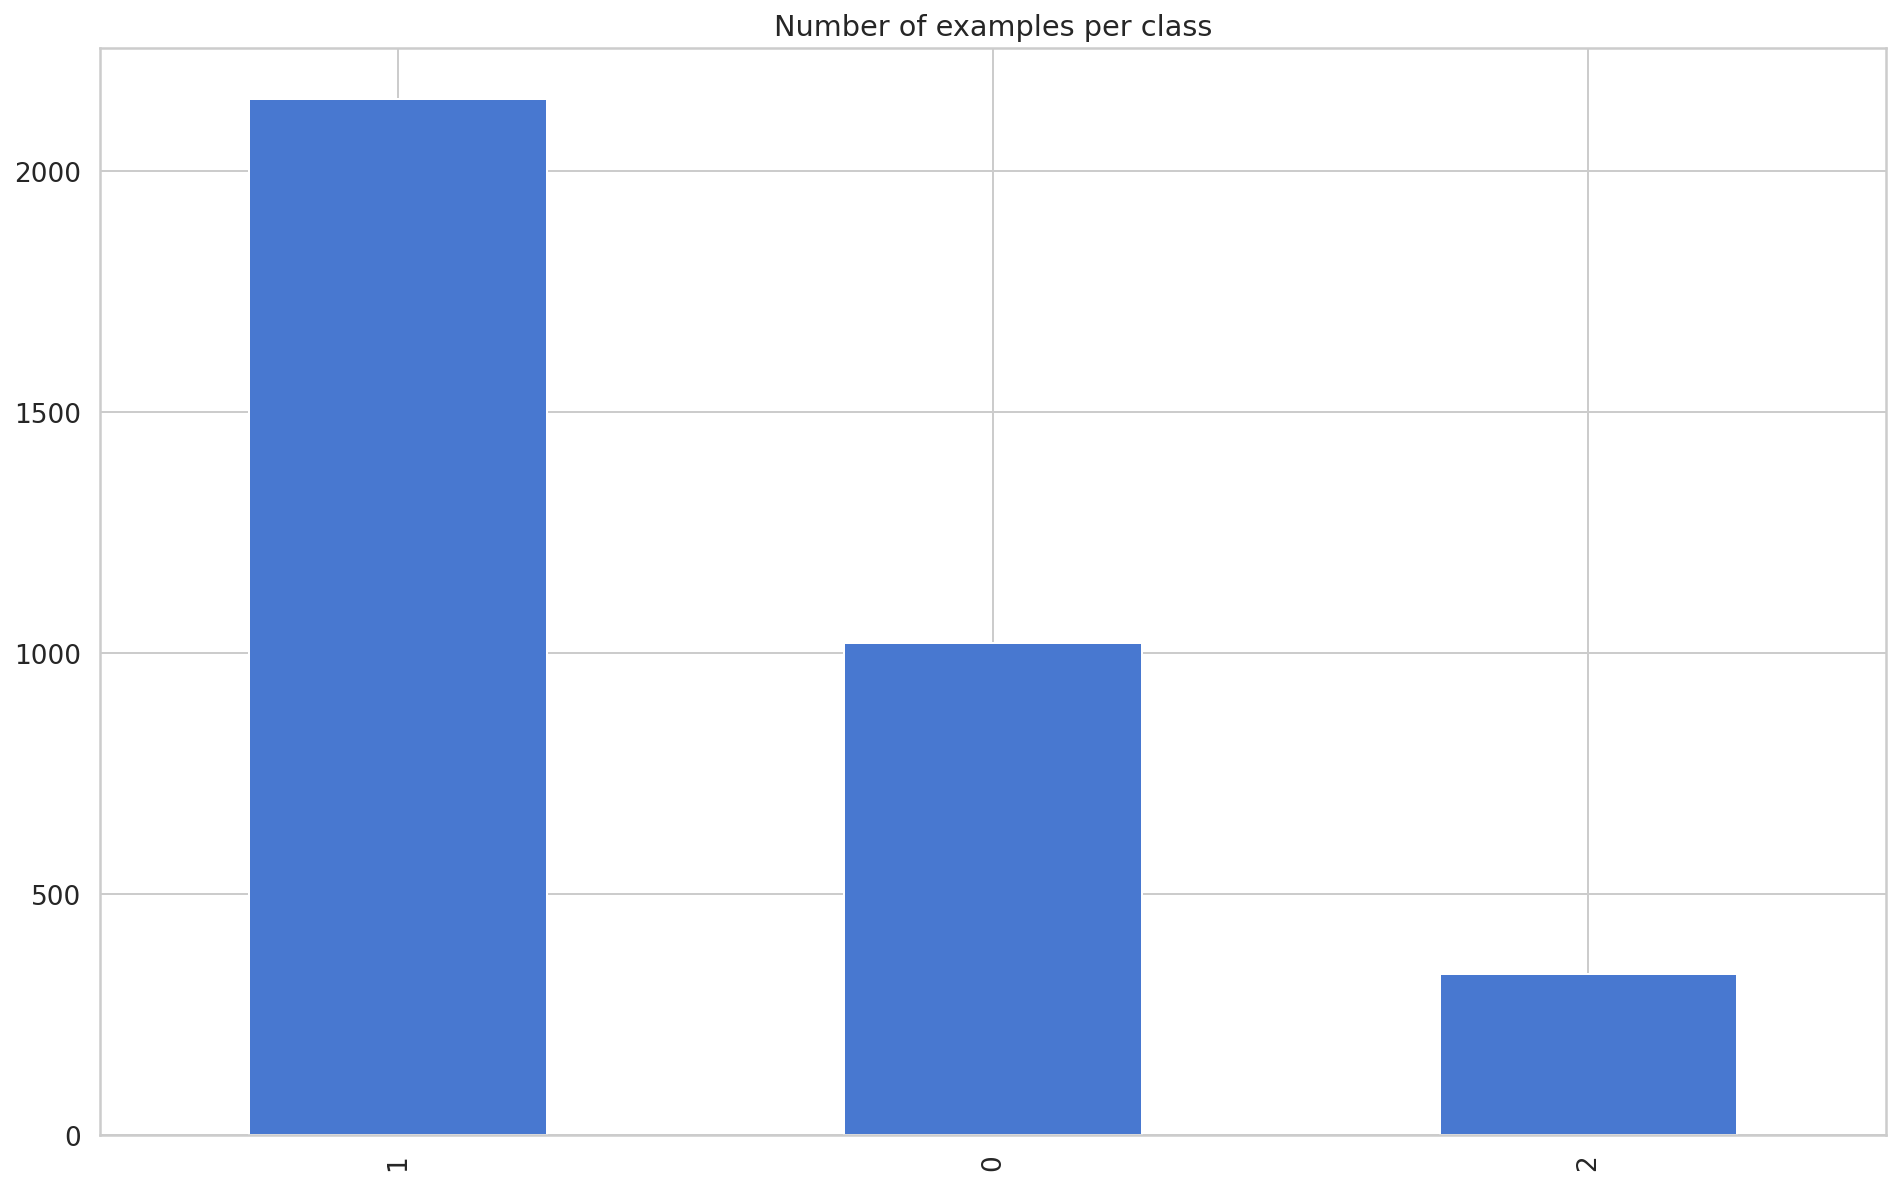

In [13]:
df['stance'].value_counts().sort_values(ascending=False).plot(kind="bar")
plt.title("Number of examples per class");

## Define specefic target

In [14]:
#Include only rows from specefic target
if Enable_TargetSpecefic == 'Yes':
  df= df[df['target'] == selectedTarget]
  test_df= test_df[test_df['target'] == selectedTarget]

print(df.shape)
print(test_df.shape)

(1190, 14)
(210, 14)


## Load data into Huggingface 

In [15]:
# load the dataset from pandas dataframe to Huggingface Dataset

tds = Dataset.from_pandas(df)
vds = Dataset.from_pandas(test_df)

loaded_datasets = DatasetDict()

loaded_datasets['train'] = tds
loaded_datasets['validation'] = vds

In [16]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date', '__index_level_0__'],
        num_rows: 1190
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date', '__index_level_0__'],
        num_rows: 210
    })
})

In [17]:
# Remove the extra column '__index_level_0__' when we convert from pandas to Huggingface
loaded_datasets = loaded_datasets.remove_columns(['__index_level_0__'])

## Preprocessing the tweets

### Regex preprocessing 

In [18]:
## Remove hashtags, URL, MENTION

def remove_hash_URL_MEN(text):
    #text = re.sub(r'#(\w+)','',text)
    text = re.sub(r'#',' ',text) #remove #
    text = re.sub(r'_',' ',text) #remove _
    text = re.sub(r'URL','',text)
    text = re.sub(r'MENTION','',text)
    return text

##  Remove punctuations

arabic_punctuations = '''`÷×؛<>()*&^%][ـ،/:"؟.,'{}~¦+|!”…“–ـ'''
english_punctuations = string.punctuation
punctuations_list = arabic_punctuations + english_punctuations

def remove_punctuations(text):
    translator = str.maketrans('', '', punctuations_list)
    return text.translate(translator)

##  Normalize_arabic

def normalize_arabic(text):
    text = re.sub("[إآ]", "ا", text)
    #text = re.sub("ى", "ي", text)
    #text = re.sub("ة", "ه", text)
    text = re.sub("گ", "ك", text)
    return text


## Remove_repeating_char

def remove_repeating_char(text):
    return re.sub(r'(.)\1+', r'\1', text)


# one4all preprocess

def processPost(tweet): 
    tweet['text']=remove_hash_URL_MEN(str(tweet['text']))

    #Replace @username with empty string
    tweet['text'] = re.sub('@[^\s]+', ' ', str(tweet['text']))
    
    #Convert www.* or https?://* to " "
    tweet['text'] = re.sub('((www\.[^\s]+)|(https?://[^\s]+))',' ',str(tweet['text']))
    
    #Replace #word with word
    #tweet['text'] = re.sub(r'#([^\s]+)', r'\1', str(tweet['text']))

    # remove punctuations
    #tweet['text']= remove_punctuations(str(tweet['text']))
    
    # normalize the tweet
    tweet['text']= normalize_arabic(str(tweet['text']))
    
    # remove repeated letters
    #tweet['text']=remove_repeating_char(str(tweet['text']))

    return tweet

In [19]:
# Regex preprocessing before tokenizing
loaded_datasets["train"] = loaded_datasets["train"].map(processPost)
loaded_datasets["validation"] = loaded_datasets["validation"].map(processPost)

In [20]:
# Sanity check on the dataset after Regex processing
list(loaded_datasets["validation"]['text'][0:20])

##Q: some emojis is not included in the vocab

['الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحيه ولا مشاهير صاحين.  الوضع الحالي اقبح صور تسليع المرأه تحت مسمى تمكين المرأه!   مقاطعة شاهي خدير',
 'انا مع تمكين المرأة اصلا ',
 'من أسباب "تمكين" المرأة المزعوم: ١-أن تستفيد الدولة الرأسمالية من الضرائب والأجور التي ستدفعها المرأة بجانب الرجل  أي ستتضاعف الضرائب والعائدات لخزينة الدولة من المواطن ٢-الغاء الأسرة وترسية قيم الفردية والأنانية وأبوية النظام (النظام هو الأب والأسرة) بلغوا من تتشدق بـ "أنا حرة"',
 '✴️تمكين المرأة اليوم: ١-تمكين الوصول الى واستغلال وامتهان وتسليع جسدها ٢-تمكين الوصول الى مالها (الدولة) ٣-تمكين استغلال جهدها الجسدي والعقلي (استعباد) ٤-تمكين عزلها عن تكوين وادارة وتربية أسرة ٥-تمكين الانفراد بها فكرياً ٦-تمكين تمردها وضلالها ٧-تمكين الشياطين والدجال منها',
 'تمكين المرأة كرامة ومساواة ',
 ' تمكين المرأه  واخر شي جامعيه كاشير ؟ لو ما انتي محتاجه اجلسي ببيتك اعز لك واكرم  ايش الشيء الي بتجنينه من الكاشير لا هو مجال دراستك ولا فيه تطوير لك',
 ' تمكين المرأة في الحياة العامة وخروجها من منزلها فهذا يعني انتكاسة للمج

### AraBERT preprocessing


In [21]:
!git clone https://github.com/aub-mind/arabert/

fatal: destination path 'arabert' already exists and is not an empty directory.


In [22]:
!pip install emoji==1.6.1

In [23]:
from arabert.preprocess import ArabertPreprocessor

#https://github.com/aub-mind/arabert/blob/master/preprocess.py
# Default values of parameters:
#ArabertPreprocessor(model_name: str, remove_html_markup: bool=True, replace_urls_emails_mentions: bool=True, strip_tashkeel: bool=True, 
#                    strip_tatweel: bool=True, insert_white_spaces: bool=True, remove_non_digit_repetition: bool=True, keep_emojis: bool=None,
#                    replace_slash_with_dash: bool=None, map_hindi_numbers_to_arabic: bool=None, apply_farasa_segmentation: bool=None)

arabert_prep = ArabertPreprocessor(model_name=model_name) #keep_emojis will be automatically set to True in AraBERT-twitter.


In [24]:
sample_tweet = test_df.iloc[1]
sample_tweet.text

'انا مع تمكين المرأة اصلا URL'

In [25]:
sample_text = arabert_prep.preprocess(sample_tweet.text)
sample_text

'انا مع تمكين المرأة اصلا URL'

In [26]:
# Convert dataset to dataframe for easy manipulation to apply arabert_prep.preprocess
df_pandas_train = pd.DataFrame(loaded_datasets['train'])
df_pandas_valid = pd.DataFrame(loaded_datasets['validation'])

# Apply arabert_prep.preprocess
df_pandas_train['text'] = df_pandas_train['text'].apply(lambda x: arabert_prep.preprocess(x))
df_pandas_valid['text'] = df_pandas_valid['text'].apply(lambda x: arabert_prep.preprocess(x))

# Recover to HF dataset
loaded_datasets['train']=loaded_datasets['train'].from_pandas(df_pandas_train)
loaded_datasets['validation']=loaded_datasets['validation'].from_pandas(df_pandas_valid)

In [27]:
# Sanity check on the dataset after arabert processing
list(loaded_datasets['train']['text'][0:20])

['عشان يلمع صورته ويعنني تمكين المرأة ويصير ترند والحكومة هي اكثر من تقمع المرأة اخر شيء كل الي فرحانين بالقرار ودارسين قانون متوظفين كاشير في مول راتبهم 3 الاف',
 "هذا ما يعرف ب ' فوبيا المرأة المتمكنة ' افة فكرية تغزو عقول بعض الرجال حيث انه اذ رأى تمكين للمرأة حتى ولو كان بسيطا فهو من المرجح بالطبع ربطه للموضوع مع - النسوية - وأتهام الفكرة بأكملها بالشيطنة والخبث .",
 'فخورين بنساء الوطن 🇸 🇦 وكلنا فخر بتقدم تمكين المرأه يوم بعد يوم ؛ الله يديم حكومتنا ؛ ويحفظ بلادنا ويعزها \U0001f90d . .',
 'هه ماعليك زمن تمكين المرأة ماراح يسوون لك شي 😂',
 'وين تمكين المرأة ؟',
 'هناك من عاصر زمن تحرير السود من العبودية وهناك من عاصر زمن تمكين المرأة واعطائها كامل حقوقها وشاء الله أن يكون زماننا زمن اعطاء الشواذ حقوقهم وهو الأسوأ حتى الان أتمنى ألا تطول صولتهم',
 'بتبرع كريم من شركة القدس للتأمين وكجزء من مسؤوليتهم المجتمعية تجاه السيدات ولدعم تمكين المرأة دربنا عدد من السيدات على أساسيات الخياطة في مشروع أرزاق . JHCO تمكين تدريب',
 'لايخدعونك بكذبة تمكين المرأة ! .',
 'اشباه الرجال حالهم ما يسر من

In [28]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 1190
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 210
    })
})

# Building The Multi-Task Dataset

1. Define the tokenizer
2. Build and tokenize the stance_dataset
3. Build and tokenize the sentiment_dataset
4. Build and tokenize the sarcasm_dataset
5. Merge all datasets

In [29]:
## Parameters
max_length= 128 
seednum= 42

In [30]:
## Define the tokenizer        
tokenizer = AutoTokenizer.from_pretrained(model_name) #,add_prefix_space=True)

In [31]:
# A class for the task, inherit from dataclass where we specifie id, name ,type,num_labels
@dataclass
class Task:
    id: int
    name: str
    type: str
    num_labels: int

### Stance dataset

In [32]:
def load_stance_dataset():
    
    task_name = 'stance'
    num_labels =3  # {'None': 2, 'Favor': 1, 'Against': 0}
    task_id=1 # id of the task

    def tokenize_text(examples):

        result = tokenizer(examples['text'], examples['target'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result
    
    raw_datasets = loaded_datasets

    ## We need to rename the column to merge all the datasets later
    raw_datasets = raw_datasets.rename_column('stance', 'label') # rename column 


    # removing the none class
    # change: num_labels =2 
    #############################################
    '''
    df_pandas_train = pd.DataFrame(raw_datasets['train'])# convert dataset to dataframe for easy manipulation
    df_pandas_valid = pd.DataFrame(raw_datasets['validation'])

    df_pandas_train=df_pandas_train[df_pandas_train['label']!=0]# remove third class (None,label=0)
    df_pandas_valid=df_pandas_valid[df_pandas_valid['label']!=0]

    # mapping to start from zero
    mapping_stance = {1: 0, 2: 1}
    df_pandas_train['label'] = df_pandas_train['label'].apply(lambda x: mapping_stance[x])
    df_pandas_valid['label'] = df_pandas_valid['label'].apply(lambda x: mapping_stance[x])
    
    raw_datasets['train']=raw_datasets['train'].from_pandas(df_pandas_train)# recover to dataset
    raw_datasets['validation']=raw_datasets['validation'].from_pandas(df_pandas_valid)

    raw_datasets = raw_datasets.remove_columns(['__index_level_0__'])# this index is added by pandas when convertint to dataset (need to be removed)
    '''
    #############################################

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info



In [33]:
load_stance_dataset()

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 1190
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 210
 }),
 Task(id=1, name='stance', type='seq_classification', num_labels=3))

### Sentiment dataset

In [34]:
def load_sentiment_dataset():
    
    task_name = 'sentiment'
    num_labels =3 # {'Neutral': 2, 'Positive': 1, 'Negative': 0}
    task_id=2
  
    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sentiment', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )

    return train_dataset,validation_dataset,task_info


In [35]:
load_sentiment_dataset()

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 1190
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 210
 }),
 Task(id=2, name='sentiment', type='seq_classification', num_labels=3))

### Sarcasm dataset

In [36]:
def load_sarcasm_dataset():
    
    task_name = 'sarcasm'
    num_labels =2 # {"Yes": 1, "No": 0}
    task_id=3

    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result


    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sarcasm', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info

In [37]:
load_sarcasm_dataset()

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 1190
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 210
 }),
 Task(id=3, name='sarcasm', type='seq_classification', num_labels=2))

### Merging the 3 datasets

In [38]:
def load_datasets():
    # load three datasets and merge it to have only one dataset 
    (
        seq_classification_train_dataset1,
        seq_classification_validation_dataset1,
        seq_classification_task1,
    ) = load_stance_dataset()

    (
        seq_classification_train_dataset2,
        seq_classification_validation_dataset2,
        seq_classification_task2,
    ) = load_sentiment_dataset()

    (
        seq_classification_train_dataset3,
        seq_classification_validation_dataset3,
        seq_classification_task3,
    ) = load_sarcasm_dataset()
 

    # Merge train datasets
    train_dataset_df = seq_classification_train_dataset1.to_pandas().append(
        seq_classification_train_dataset2.to_pandas().append(
            seq_classification_train_dataset3.to_pandas()
            )
    )

    train_dataset = datasets.Dataset.from_pandas(train_dataset_df)
    train_dataset=train_dataset.shuffle(seed=seednum)

    # Append validation datasets
    validation_dataset = [
        seq_classification_validation_dataset1,
        seq_classification_validation_dataset2,
        seq_classification_validation_dataset3
    ]

    dataset = datasets.DatasetDict(
        {"train": train_dataset, "validation": validation_dataset}
    )
    
    tasks = [seq_classification_task1, seq_classification_task2, seq_classification_task3]

    return tasks, dataset

# Multi-Task Model

1. Create attention heads
2. Define the encoder
3. Build multi-task model

In [39]:
def get_task_loss(w, loss_fct, logits, num_labels, labels, task):
    
    if task == "stance":
        factor = w
    elif task == "sentiment":
        factor = torch.div(w,2)
    elif task == "sarcasm":
        factor = torch.div(w,3)
        
    loss = factor*loss_fct(
                logits.view(-1, num_labels), labels.view(-1)
            )
             
    return loss

In [40]:
#w = nn.Parameter(torch.tensor(1,dtype=torch.float), requires_grad=True)
#w

### Stance Head

In [41]:
class SequenceClassificationHeadStance(nn.Module):
    
    def __init__(self, hidden_size, num_labels, w, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        ### W ###
        self.w = w

        self._init_weights()

    #def forward(self, sequence_output, pooled_output, labels=None, **kwargs):
    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output) #logits is the values of the predections (not between 0 and 1)

        loss = None
 
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()

            print()
            loss = get_task_loss(self.w, loss_fct, logits, self.num_labels, labels.long(), "stance")
            print("Stance loss:", loss)
             
        return logits, loss
    

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
  

### Sentiment Head

In [42]:
class SequenceClassificationHeadSentiment(nn.Module):
    
    def __init__(self, hidden_size, num_labels, w, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        ### W ###
        self.w = w

        self._init_weights()

    #def forward(self, sequence_output, pooled_output, labels=None, **kwargs):
    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
            
            loss_fct = nn.CrossEntropyLoss()
            loss = get_task_loss(self.w, loss_fct, logits, self.num_labels, labels.long(), "sentiment")
            print("Sentiment loss:", loss)

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
            

### Sarcasm Head

In [43]:
class SequenceClassificationHeadSarcasm(nn.Module):

    def __init__(self, hidden_size, num_labels, w, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        ### W ###
        self.w = w

        self._init_weights()

    #def forward(self, sequence_output, pooled_output, labels=None, **kwargs):
    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()
            loss = get_task_loss(self.w, loss_fct, logits, self.num_labels, labels.long(), "sarcasm")
            print("Sarcasm loss:", loss)

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
            

### Multi-task class

In [44]:
class MultiTaskModel(nn.Module):

    def __init__(self, model_name, tasks: List):
        super().__init__()
        

        ## Define the encoder:
        self.encoder = AutoModel.from_pretrained(model_name)

        self.output_heads = nn.ModuleDict()
        
        # creat the atrainable parameter w and pass it to all heads
        self.w = nn.Parameter(torch.tensor(1,dtype=torch.float), requires_grad=True)
        
        for task in tasks:
            decoder = self._create_output_head(self.encoder.config.hidden_size, task, self.w)
            # ModuleDict requires keys to be strings
            self.output_heads[str(task.id)] = decoder

    @staticmethod
    def _create_output_head(encoder_hidden_size: int, task, w):
        if task.name == "stance":
            return SequenceClassificationHeadStance(encoder_hidden_size, task.num_labels, w)
        elif task.name == "sarcasm":
            return SequenceClassificationHeadSarcasm(encoder_hidden_size, task.num_labels, w)
        elif task.name == "sentiment":
            return SequenceClassificationHeadSentiment(encoder_hidden_size, task.num_labels, w)
        else:
            raise NotImplementedError()
   
    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        position_ids=None,
        head_mask=None,
        inputs_embeds=None,
        labels=None,
        task_ids=None,
        **kwargs,
    ):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            position_ids=position_ids,
            head_mask=head_mask,
            inputs_embeds=inputs_embeds,
        )

        #sequence_output, pooled_output = outputs[:2]# sequence_output  are the hidden representations of all tokens 
        pooled_output = outputs[1]
        # pooler layer takes the final hidden representation of the [CLS] token (this is a vector of size 768),
        #then applies a linear layer and tanh to it
        # pooled_output=[batch_size, 768]
        
        unique_task_ids_list = torch.unique(task_ids).tolist()# unique_task_ids_list=[1,2,3] ,task_ids=[1,2,3,1,1,2,1]

        loss_list = []
        logits = None
        for unique_task_id in unique_task_ids_list:
            #task_id_filter is used to filter only the task in hand from the batch for example 
            ## ask_id_filter for task=3 ,task_id_filter=tensor([False, False, True, False, False, False, False])

            task_id_filter = task_ids == unique_task_id 
            logits, task_loss = self.output_heads[str(unique_task_id)].forward(
                #sequence_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                pooled_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                labels=None if labels is None else labels[task_id_filter],
                attention_mask=attention_mask[task_id_filter],
            )

            if labels is not None:
                loss_list.append(task_loss)

        # logits are only used for eval. and in case of eval the batch is not multi task
        # For training only the loss is used
        # outputs[2:] is the same as outputs[1] --> try it first
        outputs = (logits, outputs[2:])

        if loss_list:
            ### W1 ###
            loss = torch.stack(loss_list)
            outputs = (loss.sum(),) + outputs
            #outputs = (loss.mean(),) + outputs
            print("Total loss:", loss.sum())

        return outputs


# Training

### Loading for training

In [45]:
# Import for trainer

from transformers import Trainer, DataCollatorWithPadding
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EvalPrediction,
    HfArgumentParser,
    PretrainedConfig,
    Trainer,
    TrainingArguments,
    default_data_collator,
    set_seed,
)
 

In [46]:
# Load the multi task dataset
tasks, dataset=load_datasets()

# Build the multi task model
model=MultiTaskModel(model_name,tasks)

## pad_to_multiple_of=8 --> this just for the GPU during training
data_collator = DataCollatorWithPadding(
                        tokenizer, pad_to_multiple_of=8
                    )

# Load the train dataset
train_dataset = dataset["train"]

# Load the validation dataset
validstance, validsarcasm, validsentiment = dataset['validation']
#validstance,validsentiment=dataset['validation']


Some weights of the model checkpoint at aubmindlab/bert-base-arabertv02-twitter were not used when initializing BertModel: ['cls.predictions.transform.dense.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of BertModel were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dens

In [47]:
# We should have 1 merged dataset and 3 validation sets (one for each task)
dataset

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
        num_rows: 3570
    })
    validation: [Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 210
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 210
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 210
    })]
})

In [48]:
train_dataset

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
    num_rows: 3570
})

In [49]:
dataset['train'] = dataset['train'].remove_columns(['__index_level_0__'])

In [50]:
train_dataset = train_dataset.remove_columns(['__index_level_0__'])

### Define metrics

In [51]:
def compute_metrics(p: EvalPrediction):
    preds = np.argmax(p.predictions[0],axis=1)
    target=p.label_ids
    #print(classification_report(target,preds))
 
    return {
            "precision": round(precision_score(target, preds, average='macro'),4),
            "recall": round(recall_score(target, preds, average='macro'),4),
            "macro_f1": round(f1_score(target, preds, average='macro'),4),
            "accuracy": round(accuracy_score(target, preds),4),
        }

### Logging to WANDB

In [52]:
#!pip install wandb

In [53]:
#os.environ["WANDB_DISABLED"] = "true"

In [54]:
import wandb

In [55]:
wandb.login()

# API key:
# <removed>
# old: <removed>

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: nora_sa. Use `wandb login --relogin` to force relogin


True

In [56]:
wandb.init(project = "Multi_task", entity= "nora_sa", name = Ex_name)

In [57]:
#%env "WANDB_NOTEBOOK_NAME" "Multi_Task"

### Define Trainer

In [58]:
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark = False

In [59]:
## NEW
training_args=transformers.TrainingArguments(
        output_dir="./models",
        overwrite_output_dir=True,
        learning_rate=2e-5, #1e-5
        adam_epsilon = 1e-8,
        fp16 = True, # set this to True when using V100 or T4 GPU
        do_train=True,
        do_eval=True,
        num_train_epochs=20,
        per_device_train_batch_size = 4, #8, # up to 64 on 16GB with max len of 128
        per_device_eval_batch_size = 32, #default is 8
        gradient_accumulation_steps = 8, #4, # use this to scale batch size without needing more memory 
        #batch_size will be 32 (per_device_train_batch_size*gradient_accumulation_steps = 4*8)  
        #warmup_ratio = 0,
        #save_steps=500,
        logging_steps = 100, #default logging_steps is set to 500 steps, so no loss is reported before 500 steps (decrease it to solve No log loss issue)
        evaluation_strategy = 'epoch', #'steps', #
        save_strategy = 'epoch',
        load_best_model_at_end = True, # this allows to automatically get the best model at the end based on whatever metric we want
        metric_for_best_model = 'macro_f1',
        greater_is_better = True,
        seed = 42,
        report_to="wandb",
        run_name = Ex_name # to log the experiment in wandb
    )

set_seed(training_args.seed)


#### Some calculations:

**total_train_batch_size** = args.train_batch_size * args.gradient_accumulation_steps * args.world_size

--> total_train_batch_size = 16 * 2 * 1 = 32

-------------

**num_update_steps_per_epoch** = len(train_dataloader) / args.gradient_accumulation_steps

**len(train_dataloader)** = #batches = #samples/ args.train_batch_size = 10506 / 16 = 656

--> num_update_steps_per_epoch = 656 / 2 = 328

-------

**max_steps** = math.ceil(args.num_train_epochs * num_update_steps_per_epoch)

--> max_steps = math.ceil(20 * 328) = 6560

-------


In [60]:
trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset=validstance,
    compute_metrics=compute_metrics,
    tokenizer=tokenizer,
    data_collator=data_collator,
)

Using amp half precision backend


In [ ]:
trainer.train()


/home/eye/anaconda3/lib/python3.6/site-packages/transformers/optimization.py:309: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  FutureWarning,
***** Running training *****
  Num examples = 3570
  Num Epochs = 20
  Instantaneous batch size per device = 4
  Total train batch size (w. parallel, distributed & accumulation) = 32
  Gradient Accumulation steps = 8
  Total optimization steps = 2220
Automatic Weights & Biases logging enabled, to disable set os.environ["WANDB_DISABLED"] = "true"


Sentiment loss: tensor(0.4414, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.2935, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.7349, device='cuda:0', grad_fn=<SumBackward0>)
Sentiment loss: tensor(0.4326, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.2548, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.6874, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.9316, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.5811, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.3496, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(1.8623, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.7952, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.5920, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(1.3872, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.9474, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tens

Epoch,Training Loss,Validation Loss,Precision,Recall,Macro F1,Accuracy
0,0.828900,0.405004,0.544200,0.596400,0.566000,0.833300
1,0.536000,0.373398,0.549400,0.572600,0.560600,0.833300
2,0.424000,0.435108,0.556500,0.549200,0.548500,0.823800
3,0.306200,0.431022,0.674600,0.600100,0.613200,0.842900
4,0.221200,0.440925,0.915500,0.641200,0.651700,0.881000
5,0.183300,0.515557,0.737900,0.640700,0.664000,0.857100
6,0.140300,0.620147,0.639600,0.577000,0.592600,0.823800
7,0.110300,0.574202,0.700800,0.630400,0.651100,0.847600
8,0.070600,0.680105,0.676800,0.597500,0.612400,0.842900
9,0.029900,0.643347,0.736700,0.615500,0.628400,0.857100


Sentiment loss: tensor(0.4978, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.2182, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.7160, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.8125, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.5098, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.2441, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(1.5664, device='cuda:0', grad_fn=<SumBackward0>)
Sarcasm loss: tensor(0.2178, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.2178, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.6504, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.4883, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.1809, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(1.3196, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(1.1113, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0

***** Running Evaluation *****
  Num examples = 210
  Batch size = 32


tensor(0.2812, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.3223, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.6036, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.2418, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.0527, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.0355, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.3300, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.7772, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.0913, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.0236, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.8921, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.0493, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.0777, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.1270, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.3775, devic

... (50 outputs left out)

***** Running Evaluation *****
  Num examples = 210
  Batch size = 32



Stance loss: tensor(0.0011, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.0027, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.0037, device='cuda:0', grad_fn=<SumBackward0>)
Sarcasm loss: tensor(0.0005, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.0005, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.8758, device='cuda:0')
Total loss: tensor(0.8758, device='cuda:0')

Stance loss: tensor(1.2650, device='cuda:0')
Total loss: tensor(1.2650, device='cuda:0')

Stance loss: tensor(0.7518, device='cuda:0')
Total loss: tensor(0.7518, device='cuda:0')

Stance loss: tensor(0.1891, device='cuda:0')
Total loss: tensor(0.1891, device='cuda:0')

Stance loss: tensor(0.2073, device='cuda:0')
Total loss: tensor(0.2073, device='cuda:0')

Stance loss: tensor(0.8735, device='cuda:0')
Total loss: tensor(0.8735, device='cuda:0')

Stance loss: tensor(1.2078, device='cuda:0')
Total loss: tensor(1.2078, device='cuda:0')


Saving model checkpoint to ./models/checkpoint-1554
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-1554/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-1554/special_tokens_map.json


Sentiment loss: tensor(0.0019, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.0004, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.0023, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.0006, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.0004, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.0010, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.0025, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(0.0004, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.0029, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.0006, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tensor(0.0006, device='cuda:0', grad_fn=<MulBackward0>)
Sarcasm loss: tensor(7.5828e-05, device='cuda:0', grad_fn=<MulBackward0>)
Total loss: tensor(0.0012, device='cuda:0', grad_fn=<SumBackward0>)

Stance loss: tensor(0.0003, device='cuda:0', grad_fn=<MulBackward0>)
Sentiment loss: tens

# Evaluation

In [ ]:
# Get predictions
preds_target = trainer.predict(validstance)

print(compute_metrics(preds_target))

In [ ]:
pt=preds_target

preds = np.argmax(pt.predictions[0],axis=1)
target=pt.label_ids

#print(preds)
#print(target)

report_test = classification_report(target, preds, zero_division=0, digits=4)
print(report_test)

In [ ]:
report_test = classification_report(target, preds, zero_division=0, digits=4, output_dict=True)
report_df = pd.DataFrame(report_test).transpose()

In [ ]:
tbl = wandb.Table(dataframe=report_df)

wandb.log({Ex_name: tbl})

In [ ]:
cf_matrix = confusion_matrix(target, preds)
print(cf_matrix)

In [ ]:
class_names = ['Against','Favor','None']

In [ ]:
#visualize confusion matrix

cm_df = np.asarray(cf_matrix).reshape(3,3)

print(cm_df.shape)
plt.figure(figsize = (10,10))
sns.heatmap(cm_df, annot=True, fmt='', cmap='Blues',annot_kws={"size": 16}, xticklabels=class_names, yticklabels=class_names)
plt.show()

# Write results

In [ ]:
# Change directory to save the results
path = "Results/"
%cd $path

In [ ]:
ex_report_test = classification_report(target, preds, target_names=class_names, zero_division=0, digits=4, output_dict=True)

print(ex_report_test)

df_report_test = pd.DataFrame(ex_report_test).transpose()

df_report_test.to_csv(Ex_name+'_Test_report.csv', sep=',')

# Save and Load the model

In [ ]:
##Q: What code can be used for saving and loading the model?

In [ ]:
#[CLS]target[SEP]sentence[SEP]